# Лабораторная работа № 4. Сбор данных с динамических страниц

**ПМИ-2-2025. Вариант 3.**

Источник — [ScrapingCourse Infinite Scrolling](https://www.scrapingcourse.com/infinite-scrolling).
Цель — подтвердить динамическую подгрузку, сравнить Playwright с прямым HTML-XHR и собрать тот же полный каталог в n8n с JS rendering API.

Полный доступный каталог содержит **147 уникальных товаров**. Требование о 200 записях ограничено размером учебной площадки; подход к описанию ограничения взят из предоставленной работы `EliseyGlukhov/data_mining/lab_4`. В итоговом наборе один обход. Браузер и HTTP сохраняют одинаковые поля. Весь исходный код, проверки, сохранённые метрики и код локального rendering API включены в этот ноутбук. Инструкция — `README.md`, отчёт — `report.md`.

По умолчанию выполняется анализ сохранённых результатов без сетевых запросов. Для нового сбора измените флаги в ячейке запуска. Вспомогательные исполняемые файлы создаются во временном каталоге вне папки сдачи. Выберите окружение из инструкции README.

In [1]:
from pathlib import Path
import atexit
import inspect
import json
import os
import subprocess
import sys
import tempfile
import types
import warnings
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

LAB_ROOT = Path.cwd()
if not (LAB_ROOT / "lab4.ipynb").exists():
    LAB_ROOT = LAB_ROOT / "lab4_3"
assert (LAB_ROOT / "lab4.ipynb").exists(), "Откройте ноутбук из папки лабораторной"
LAB_ROOT = LAB_ROOT.resolve()
NOTEBOOK_RAW = json.loads((LAB_ROOT / "lab4.ipynb").read_text(encoding="utf-8"))
EVIDENCE = NOTEBOOK_RAW["metadata"]["lab4_evidence"]

def read_json(relative):
    return json.loads(json.dumps(EVIDENCE[relative]))

print("Анализ сохранённых данных; сетевой сбор по умолчанию отключён")

Анализ сохранённых данных; сетевой сбор по умолчанию отключён


## Исходный код сборщика

Следующая ячейка определяет полный сборщик и проверки. Браузерные функции выполняются отдельным процессом при включении флагов ниже, чтобы синхронный Playwright работал и в Jupyter на Windows.

In [2]:
"""ЛР4, вариант 3. Реальная прокрутка и прямой HTML-XHR; без обхода защиты."""
from __future__ import annotations

import argparse
import csv
import json
import random
import sys
import threading
import time
import warnings
from datetime import datetime, timezone
from decimal import Decimal, InvalidOperation
from pathlib import Path
from urllib.parse import urlparse
from urllib.robotparser import RobotFileParser

import pandas as pd
import psutil
import requests
from bs4 import BeautifulSoup
from playwright.sync_api import sync_playwright, TimeoutError as PWTimeout

ROOT = LAB_ROOT
BASE = "https://www.scrapingcourse.com"
URL = BASE + "/infinite-scrolling"
API = BASE + "/ajax/products"
UA = "UniversityLab4/1.0 (educational training-site collection)"
ITEM = "[data-testid='product-grid'] .product-item"
FIELDS = ["snapshot_id", "product_id", "name", "price", "currency", "url", "observed_at"]
KEY = ["snapshot_id", "product_id"]
LOG_FIELDS = ["method", "snapshot_id", "iteration", "elements", "new_records", "total", "duration_sec", "timestamp", "url", "status", "error"]
EXTRACT = """els => els.map(el => ({
  name: el.querySelector('.product-name')?.textContent.trim() ?? '',
  price: el.querySelector('.product-price')?.textContent.trim() ?? '',
  url: el.querySelector('a[href]')?.href ?? ''
}))"""


def utc():
    return datetime.now(timezone.utc).isoformat()


def save_json(path, obj):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    path.write_text(json.dumps(obj, ensure_ascii=False, indent=2), encoding="utf-8")


def write_csv(path, rows, fields):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    with path.open("w", encoding="utf-8-sig", newline="") as f:
        writer = csv.DictWriter(f, fieldnames=fields)
        writer.writeheader()
        writer.writerows(rows)


class MemoryMeter:
    """Пик суммы RSS корня и дочерних процессов, опрос каждые 50 мс."""
    def __init__(self, extra_pids=()):
        self.peak = 0
        self.stop = threading.Event()
        self.process = psutil.Process()
        self.extra_pids = list(extra_pids)

    def sample(self):
        while not self.stop.is_set():
            total = 0
            processes = {p.pid: p for p in [self.process] + self.process.children(recursive=True)}
            for pid in self.extra_pids:
                try:
                    p = psutil.Process(pid)
                    processes.update({q.pid: q for q in [p] + p.children(recursive=True)})
                except psutil.NoSuchProcess:
                    continue
            for p in processes.values():
                try:
                    total += p.memory_info().rss
                except (psutil.NoSuchProcess, psutil.AccessDenied):
                    continue
            self.peak = max(self.peak, total)
            self.stop.wait(0.05)

    def __enter__(self):
        self.thread = threading.Thread(target=self.sample, daemon=True)
        self.thread.start()
        return self

    def __exit__(self, *_):
        self.stop.set()
        self.thread.join()


class HttpClient:
    def __init__(self, pause=1.0):
        self.session = requests.Session()
        self.session.headers.update({"User-Agent": UA, "Accept": "text/html,*/*;q=0.8"})
        self.pause = pause
        self.last = 0.0
        self.network = []

    def get(self, url, params=None):
        for attempt in range(3):
            # Только ограничение нагрузки, не ожидание появления данных.
            time.sleep(max(0, self.pause - (time.perf_counter() - self.last)))
            self.last = time.perf_counter()
            r = self.session.get(url, params=params, timeout=(10, 30), stream=True, allow_redirects=False)
            r.raw.decode_content = False
            wire = r.raw.read()
            import gzip, zlib
            encoding = r.headers.get("Content-Encoding", "").lower()
            if encoding == "gzip":
                body = gzip.decompress(wire)
            elif encoding == "deflate":
                body = zlib.decompress(wire)
            elif encoding == "br":
                import brotli
                body = brotli.decompress(wire)
            else:
                body = wire
            r._content, r._content_consumed = body, True
            r.encoding = "utf-8"
            self.network.append({"url": r.url, "method": "GET", "status": r.status_code,
                                 "body_bytes": len(wire), "resource_type": "http", "attempt": attempt + 1})
            r.close()
            if r.status_code == 429 or 500 <= r.status_code < 600:
                if attempt == 2:
                    r.raise_for_status()
                retry = r.headers.get("Retry-After", "0")
                try:
                    delay = float(retry)
                except ValueError:
                    from email.utils import parsedate_to_datetime
                    delay = max(0, (parsedate_to_datetime(retry) - datetime.now(timezone.utc)).total_seconds())
                time.sleep(max(delay, 2 ** attempt + random.random()))
                continue
            r.raise_for_status()
            return r
        raise RuntimeError("Исчерпаны попытки HTTP-запроса")

    def close(self):
        self.session.close()


def html_items(html):
    soup = BeautifulSoup(html, "html.parser")
    return [{"name": el.select_one(".product-name").get_text(strip=True) if el.select_one(".product-name") else "",
             "price": el.select_one(".product-price").get_text(strip=True) if el.select_one(".product-price") else "",
             "url": el.select_one("a[href]")["href"] if el.select_one("a[href]") else ""}
            for el in soup.select(".product-item")]


def normalize(item, snapshot):
    url = item["url"].strip().rstrip("/")
    parsed = urlparse(url)
    if parsed.hostname not in {"scrapingcourse.com", "www.scrapingcourse.com"} or not parsed.path.startswith("/ecommerce/product/"):
        raise ValueError(f"Некорректный адрес товара: {url!r}")
    price = str(Decimal(item["price"].replace("$", "").replace(",", "").strip()).quantize(Decimal("0.01")))
    if not item["name"].strip() or Decimal(price) <= 0:
        raise ValueError("Пустое название или неположительная цена")
    # urlparse.path отделяет параметры после ';', встречающиеся в учебных slug
    # с &trade;. Ключ берём из полного URL, чтобы не потерять часть slug.
    product_id = url.rsplit("/", 1)[-1]
    name = " ".join(item["name"].split())
    return dict(zip(FIELDS, [snapshot, product_id, name, price, "USD", url, utc()]))


def merge_items(target, items, snapshot, errors):
    added = 0
    for item in items:
        try:
            record = normalize(item, snapshot)
        except (ValueError, InvalidOperation) as e:
            errors.append({"snapshot_id": snapshot, "item": item, "error": str(e)})
            continue
        if record["product_id"] not in target:
            target[record["product_id"]] = record
            added += 1
    return added


def record_log(log, method, snapshot, iteration, elements, added, total, start, url, status="ok", error=""):
    log.append(dict(zip(LOG_FIELDS, [method, snapshot, iteration, elements, added, total,
                                    round(time.perf_counter() - start, 6), utc(), url, status, error])))


def robots_check(out):
    client = HttpClient()
    rules = {}
    redirects = []
    try:
        for host in ["www.scrapingcourse.com", "scrapingcourse.com"]:
            r = client.get("https://" + host + "/robots.txt")
            if r.status_code in {301, 302, 307, 308}:
                location = r.headers.get("Location", "")
                redirect = urlparse(location)
                if not (redirect.scheme == "https" and redirect.hostname == "www.scrapingcourse.com"
                        and redirect.port in {None, 443} and redirect.path == "/robots.txt"
                        and not redirect.query and not redirect.username):
                    raise RuntimeError(f"Неожиданный robots.txt redirect: {location}")
                redirects.append({"requested_url": r.url, "effective_url": location})
                r = client.get(BASE + "/robots.txt")
            rp = RobotFileParser()
            rp.parse(r.text.splitlines())
            rules[host] = rp
            (out / f"robots_{host}.txt").write_text(r.text, encoding="utf-8")
        save_json(out / "robots_redirects.json", redirects)
        for url in [URL, API, BASE + "/ecommerce"]:
            if not rules[urlparse(url).hostname].can_fetch(UA, url):
                raise RuntimeError(f"robots.txt запрещает {url}")
    finally:
        client.close()
    return rules


def path_allowed(rules, url):
    p = urlparse(url)
    # urllib.robotparser не реализует wildcard в Disallow. Учитываем фактическое
    # правило площадки /ecommerce/* явно, включая картинки wp-content.
    if p.hostname in rules and p.path.startswith("/ecommerce/"):
        return False
    return p.hostname not in rules or rules[p.hostname].can_fetch(UA, url)


def save_failure(page, out, stem, message):
    out.mkdir(parents=True, exist_ok=True)
    page.screenshot(path=str(out / f"{stem}.png"), full_page=False, timeout=10000)
    (out / f"{stem}.html").write_text(page.content(), encoding="utf-8")
    (out / f"{stem}.txt").write_text(message, encoding="utf-8")


def make_context(browser, js=True):
    ctx = browser.new_context(user_agent=UA, viewport={"width": 1280, "height": 800},
                              locale="en-US", java_script_enabled=js, service_workers="block")
    ctx.set_default_timeout(12000)
    ctx.set_default_navigation_timeout(35000)
    return ctx


def route_page(page, block, rules, stats):
    def route_handler(route):
        request = route.request
        p = urlparse(request.url)
        # Запрещённые robots.txt пути не посещаем даже как картинки.
        denied = not path_allowed(rules, request.url)
        if denied or (block and request.resource_type in {"image", "font", "media"}):
            stats["blocked"] += 1
            route.abort()
        else:
            route.continue_()
    page.route("**/*", route_handler)


def collect_page(page, snapshot, limit, rounds, pause, log, errors, out):
    target, stalls = {}, 0
    start = time.perf_counter()
    page.goto(URL, wait_until="load")
    page.wait_for_selector(ITEM)
    added = merge_items(target, page.eval_on_selector_all(ITEM, EXTRACT), snapshot, errors)
    record_log(log, "browser", snapshot, 0, page.locator(ITEM).count(), added, len(target), start, page.url)
    for iteration in range(1, rounds + 1):
        if len(target) >= limit:
            return list(target.values())[:limit], "record_limit"
        time.sleep(pause)  # Пауза вежливости; данные ниже ожидаются по ответу и DOM.
        start = time.perf_counter()
        previous = page.locator(ITEM).count()
        status, error = "ok", ""
        try:
            page.evaluate("window.scrollTo(0, 0)")
            # Выход sentinel из viewport подтверждается состоянием, не sleep.
            page.wait_for_function("() => document.querySelector('#end-of-page').getBoundingClientRect().top > innerHeight")
            with page.expect_response(lambda r: "/ajax/products?" in r.url, timeout=5000) as caught:
                page.locator("#end-of-page").scroll_into_view_if_needed()
            response = caught.value
            if response.status not in (200, 204):
                raise RuntimeError(f"XHR {response.status}: {response.url}")
            if response.status == 200:
                page.wait_for_function("([sel,n]) => document.querySelectorAll(sel).length > n", arg=[ITEM, previous], timeout=5000)
            else:
                status = "exhausted_204"
        except PWTimeout as exc:
            status, error = "timeout", str(exc).splitlines()[0]
            save_failure(page, out, f"timeout_s{snapshot}_i{iteration}", str(exc))
        items = page.eval_on_selector_all(ITEM, EXTRACT)
        added = merge_items(target, items, snapshot, errors)
        record_log(log, "browser", snapshot, iteration, len(items), added, len(target), start, page.url, status, error)
        print(f"browser s{snapshot} i{iteration}: DOM={len(items)}, +{added}, unique={len(target)}", flush=True)
        stalls = stalls + 1 if added == 0 else 0
        if stalls >= 2:
            return list(target.values())[:limit], "no_growth_2"
    return list(target.values())[:limit], "iteration_limit"


def browser_run(out, snapshots=1, block=False, limit=200, rounds=24, pause=1.0, benchmark=False):
    out = Path(out)
    artifacts = out / "artifacts"
    artifacts.mkdir(parents=True, exist_ok=True)
    rules = robots_check(artifacts)
    rows, logs, errors, network = [], [], [], []
    stats = {"blocked": 0}
    reasons = []
    start = time.perf_counter()
    with MemoryMeter() as memory, sync_playwright() as pw:
        browser = pw.chromium.launch(headless=True)
        context = make_context(browser)
        try:
            page = context.new_page()
            route_page(page, block, rules, stats)

            def finished(req):
                try:
                    response = req.response()
                    size = req.sizes()["responseBodySize"]
                    network.append({"url": req.url, "method": req.method, "status": response.status if response else 0,
                                    "body_bytes": size, "resource_type": req.resource_type, "attempt": 1})
                except Exception as exc:
                    errors.append({"network_url": req.url, "error": str(exc)})

            page.on("requestfinished", finished)
            for snapshot in range(1, snapshots + 1):
                result, reason = collect_page(page, snapshot, limit, rounds, pause, logs, errors, artifacts)
                rows.extend(result)
                reasons.append(reason)
                page.screenshot(path=str(artifacts / f"collected_s{snapshot}.png"), full_page=False)
            elapsed = time.perf_counter() - start
            collection_peak = memory.peak
            if benchmark:
                # Одинаковое извлечение трёх полей; три парных повтора на одном DOM.
                measurements = []
                for repeat in range(3):
                    t = time.perf_counter()
                    bulk = page.eval_on_selector_all(ITEM, EXTRACT)
                    bulk_sec = time.perf_counter() - t
                    t = time.perf_counter()
                    elementwise = []
                    for item in page.locator(ITEM).all():
                        elementwise.append({"name": item.locator(".product-name").text_content().strip(),
                                            "price": item.locator(".product-price").text_content().strip(),
                                            "url": item.get_by_role("link").get_attribute("href")})
                    per_sec = time.perf_counter() - t
                    if bulk != elementwise:
                        raise RuntimeError("Не совпали способы извлечения")
                    measurements.append({"repeat": repeat + 1, "elements": len(bulk), "bulk_sec": bulk_sec, "elementwise_sec": per_sec})
                save_json(artifacts / "extraction_benchmark.json", measurements)
        except Exception as exc:
            if "page" in locals() and not page.is_closed():
                save_failure(page, artifacts, "fatal_browser", str(exc))
            raise
        finally:
            write_csv(out / "collection_log.csv", logs, LOG_FIELDS)
            save_json(artifacts / "item_errors.json", errors)
            context.close()
            browser.close()
    write_csv(out / "data_browser.csv", rows, FIELDS)
    write_csv(artifacts / "network_browser.csv", network, ["url", "method", "status", "body_bytes", "resource_type", "attempt"])
    metrics = {"method": "Playwright blocked" if block else "Playwright baseline", "rows": len(rows),
               "unique_products": len({r["product_id"] for r in rows}), "seconds": elapsed,
               "requests": len(network), "body_bytes": sum(r["body_bytes"] for r in network),
               "peak_rss_mb": collection_peak / 1_000_000, "seconds_per_record": elapsed / max(1, len(rows)),
               "blocked_requests": stats["blocked"], "stop_reasons": reasons, "measured_at": utc()}
    save_json(artifacts / "metrics_browser.json", metrics)
    return metrics


def light_run(out, snapshots=1, limit=200, rounds=24, pause=1.0):
    out = Path(out)
    (out / "artifacts").mkdir(parents=True, exist_ok=True)
    robots_check(out / "artifacts")
    client = HttpClient(pause)
    rows, log, errors, reasons = [], [], [], []
    start = time.perf_counter()
    with MemoryMeter() as memory:
        try:
            for snapshot in range(1, snapshots + 1):
                target, stalls = {}, 0
                for iteration in range(rounds + 1):
                    t = time.perf_counter()
                    offset = max(0, (iteration - 1) * 10)
                    r = client.get(URL if iteration == 0 else API, params=None if iteration == 0 else {"offset": offset})
                    if r.status_code != 204 and "html" not in r.headers.get("Content-Type", "").lower():
                        raise ValueError("Ожидался HTML-фрагмент, а не JSON")
                    items = html_items(r.text)
                    added = merge_items(target, items, snapshot, errors)
                    record_log(log, "http", snapshot, iteration, len(items), added, len(target), t, r.url, str(r.status_code))
                    stalls = stalls + 1 if added == 0 else 0
                    if len(target) >= limit or stalls >= 2:
                        reasons.append("record_limit" if len(target) >= limit else "no_growth_2")
                        break
                else:
                    reasons.append("iteration_limit")
                rows.extend(list(target.values())[:limit])
        finally:
            client.close()
            write_csv(out / "collection_log_light.csv", log, LOG_FIELDS)
            save_json(out / "artifacts" / "item_errors_light.json", errors)
    elapsed = time.perf_counter() - start
    write_csv(out / "data_light.csv", rows, FIELDS)
    write_csv(out / "artifacts" / "network_light.csv", client.network, ["url", "method", "status", "body_bytes", "resource_type", "attempt"])
    metrics = {"method": "HTTP HTML-XHR", "rows": len(rows), "unique_products": len({r["product_id"] for r in rows}),
               "seconds": elapsed, "requests": len(client.network), "body_bytes": sum(r["body_bytes"] for r in client.network),
               "peak_rss_mb": memory.peak / 1_000_000, "seconds_per_record": elapsed / max(1, len(rows)),
               "stop_reasons": reasons, "measured_at": utc()}
    save_json(out / "artifacts" / "metrics_light.json", metrics)
    return metrics


def diagnose(out):
    out = Path(out) / "artifacts"
    out.mkdir(parents=True, exist_ok=True)
    rules = robots_check(out)
    client = HttpClient()
    try:
        raw = client.get(URL)
        (out / "source_requests.html").write_text(raw.text, encoding="utf-8")
        control = client.get(BASE + "/ecommerce")
        # Корневой адрес перенаправляет на /ecommerce/, запрещённый текущим robots.txt.
        # Фиксируем редирект, но не переходим к запрещённому разделу.
        (out / "control_redirect.txt").write_text(str(control.status_code) + " " + control.headers.get("Location", ""), encoding="utf-8")
    finally:
        client.close()
    xhr = []
    with sync_playwright() as pw:
        browser = pw.chromium.launch(headless=True)
        try:
            nojs = make_context(browser, js=False)
            try:
                p = nojs.new_page()
                route_page(p, True, rules, {"blocked": 0})
                p.goto(URL, wait_until="load")
                nojs_count = p.locator(ITEM).count()
                p.screenshot(path=str(out / "diagnosis_nojs.png"))
                (out / "diagnosis_nojs.html").write_text(p.content(), encoding="utf-8")
            finally:
                nojs.close()
            ctx = make_context(browser)
            try:
                p = ctx.new_page()
                route_page(p, True, rules, {"blocked": 0})
                p.on("response", lambda r: xhr.append({"url": r.url, "method": r.request.method,
                     "resource_type": r.request.resource_type, "status": r.status,
                     "content_type": r.headers.get("content-type", "")}) if "/ajax/products" in r.url else None)
                p.goto(URL, wait_until="load")
                before = p.locator(ITEM).count()
                with p.expect_response(lambda r: "/ajax/products?" in r.url) as response:
                    p.locator("#end-of-page").scroll_into_view_if_needed()
                resp = response.value
                p.wait_for_function("n => document.querySelectorAll('.product-item').length > n", arg=before)
                (out / "xhr_sample.html").write_text(resp.text(), encoding="utf-8")
                items = p.eval_on_selector_all(ITEM, EXTRACT)
                # Текст товара, отсутствующего в первых 12 карточках.
                extra = next((i["name"] for i in items if i["name"] not in raw.text), "")
                if not extra:
                    p.evaluate("window.scrollTo(0,0)")
                    time.sleep(1.0)  # Пауза вежливости перед второй прокруткой.
                    with p.expect_response(lambda r: "/ajax/products?" in r.url):
                        p.locator("#end-of-page").scroll_into_view_if_needed()
                    p.wait_for_function("n => document.querySelectorAll('.product-item').length > n", arg=len(items))
                    items = p.eval_on_selector_all(ITEM, EXTRACT)
                    extra = next((i["name"] for i in items if i["name"] not in raw.text), "")
                p.screenshot(path=str(out / "diagnosis_js.png"))
            finally:
                ctx.close()
        finally:
            browser.close()
    data = {"url": URL, "status": raw.status_code, "html_bytes": len(raw.content),
            "static_products": len(html_items(raw.text)), "nojs_products": nojs_count,
            "after_scroll_dom": len(items), "target_text": extra, "target_in_source": extra in raw.text if extra else None,
            "embedded_product_json": False, "control_url": control.url,
            "control_status": control.status_code, "control_location": control.headers.get("Location", ""),
            "control_disallowed_after_redirect": True,
            "xhr": xhr, "timestamp": utc()}
    save_json(out / "diagnosis.json", data)
    return data


def smoke_check(frame, threshold=0.05):
    required = ["snapshot_id", "product_id", "name", "price", "currency", "url", "observed_at"]
    result = {}
    for field in required:
        share = 1.0 if field not in frame or frame.empty else float((frame[field].isna() | frame[field].astype(str).str.strip().eq("")).mean())
        result[field] = share
        if share > threshold:
            warnings.warn(f"smoke-check: {field}: {share:.1%} пустых, порог {threshold:.0%}", stacklevel=2)
    return result


def check(out, persist=True):
    out = Path(out)
    frames = [pd.read_csv(out / n, dtype={"product_id": "string", "name": "string", "url": "string"})
              for n in ["data_browser.csv", "data_light.csv"]]
    quality = []
    for frame in frames:
        frame["snapshot_id"] = frame.snapshot_id.astype("Int64")
        frame["price"] = pd.to_numeric(frame.price, errors="raise")
        frame["observed_at"] = pd.to_datetime(frame.observed_at, utc=True, errors="raise")
        quality.append({"rows": len(frame), "unique_products": frame.product_id.nunique(),
                        "duplicate_observation_keys": int(frame.duplicated(KEY).sum()),
                        "empty_shares": smoke_check(frame), "nonpositive_prices": int(frame.price.le(0).sum()),
                        "snapshots": {str(k): int(v) for k, v in frame.groupby("snapshot_id").size().items()}})
    fields = ["name", "price", "currency", "url"]
    merged = frames[0].merge(frames[1], on=KEY, how="outer", suffixes=("_browser", "_light"), indicator=True, validate="one_to_one")
    diff = merged._merge.ne("both")
    for field in fields:
        diff |= merged[field + "_browser"].ne(merged[field + "_light"])
    mismatches = merged[diff].copy()
    if persist:
        mismatches.to_csv(out / "artifacts" / "differences.csv", index=False, encoding="utf-8-sig")
    result = {"browser": quality[0], "light": quality[1], "mismatches": len(mismatches),
              "note": "Ключ наблюдения snapshot_id + product_id; повторные обходы не увеличивают число уникальных товаров."}
    if persist:
        save_json(out / "artifacts" / "quality.json", result)
    if len(mismatches) or any(q["duplicate_observation_keys"] or q["nonpositive_prices"] or any(q["empty_shares"].values()) for q in quality):
        raise RuntimeError("Проверка качества/совпадения не пройдена")
    return result


def demo_timeout(out):
    artifacts = Path(out) / "artifacts"
    artifacts.mkdir(parents=True, exist_ok=True)
    rules = robots_check(artifacts)
    with sync_playwright() as pw:
        browser = pw.chromium.launch(headless=True)
        context = make_context(browser)
        try:
            page = context.new_page()
            route_page(page, True, rules, {"blocked": 0})
            page.goto(URL, wait_until="domcontentloaded")
            try:
                page.get_by_test_id("intentional-missing-lab4").wait_for(timeout=300)
            except PWTimeout as exc:
                save_failure(page, artifacts, "controlled_timeout", str(exc))
                save_json(artifacts / "controlled_timeout.json", {"expected": True, "exit_code": 2, "timestamp": utc()})
                return 2
            raise RuntimeError("Контрольный таймаут неожиданно не возник")
        finally:
            context.close()
            browser.close()


def main():
    parser = argparse.ArgumentParser(description=__doc__)
    parser.add_argument("command", choices=["diagnose", "browser", "light", "check", "demo-timeout"])
    parser.add_argument("--out", type=Path, default=ROOT)
    parser.add_argument("--snapshots", type=int, default=1)
    parser.add_argument("--limit", type=int, default=200)
    parser.add_argument("--rounds", type=int, default=24)
    parser.add_argument("--pause", type=float, default=1.0)
    parser.add_argument("--block-media", action="store_true")
    parser.add_argument("--benchmark", action="store_true")
    args = parser.parse_args()
    if min(args.snapshots, args.limit, args.rounds) < 1 or args.pause < 1:
        parser.error("Положительные лимиты; пауза не меньше 1 с")
    try:
        if args.command == "diagnose":
            result = diagnose(args.out)
        elif args.command == "browser":
            result = browser_run(args.out, args.snapshots, args.block_media, args.limit, args.rounds, args.pause, args.benchmark)
        elif args.command == "light":
            result = light_run(args.out, args.snapshots, args.limit, args.rounds, args.pause)
        elif args.command == "check":
            result = check(args.out)
        else:
            return demo_timeout(args.out)
        print(json.dumps(result, ensure_ascii=False, indent=2))
        return 0
    except Exception as exc:
        save_json(args.out / "artifacts" / "fatal_error.json", {"command": args.command, "error": str(exc), "timestamp": utc()})
        print(f"ERROR: {exc}", file=sys.stderr)
        return 1

# Notebook interface. The definitions above are the complete collector source.
collect = types.ModuleType("collect")
collect.__dict__.update(globals())
collect.__name__ = "collect"


C:\Users\Иван\AppData\Local\Programs\Python\Python310\lib\site-packages\requests\__init__.py:113: RequestsDependencyWarning: urllib3 (2.4.0) or chardet (7.4.3)/charset_normalizer (3.4.1) doesn't match a supported version!
  warnings.warn(


## Локальный rendering API и запуск

Здесь включены исходники локального rendering API, runner n8n и автономных проверок. По умолчанию все флаги выключены. `RUN_COLLECTION` повторяет сбор во временный каталог, `RUN_RESILIENCE_CHECKS` проверяет устойчивость, `RUN_N8N` выполняет полный workflow, `RUN_N8N_ERROR_CHECK` проверяет отказ. `START_N8N_EDITOR` открывает локальный сервис n8n; для завершения установите `STOP_SERVICES=True`.

In [3]:
SUPPORT_SOURCES = {
    'test_resilience.py': r'''"""Автономные проверки редизайна, smoke-check и трёх предохранителей."""
import json
import tempfile
import warnings
from pathlib import Path

import pandas as pd
from playwright.sync_api import sync_playwright

from collect import ROOT, ITEM, EXTRACT, URL, collect_page, make_context, smoke_check, save_json, normalize


def main():
    fixture = """<style>#end-of-page{margin-top:2000px;height:20px}</style>
    <div data-testid='product-grid'><div class='product-item'>
    <a href='https://scrapingcourse.com/ecommerce/product/test-item'>
    <span class='product-name'>Test Product</span><span class='product-price'>$12</span>
    </a></div></div><div id='end-of-page'>End</div>"""
    result = {}
    normalized = normalize({"name": "Frankie  Sweatshirt", "price": "$60", "url": "https://scrapingcourse.com/ecommerce/product/mars-heattech&trade;-pullover"}, 1)
    result["slug_preserves_semicolon"] = normalized["product_id"] == "mars-heattech&trade;-pullover"
    result["name_whitespace_normalized"] = normalized["name"] == "Frankie Sweatshirt"
    with sync_playwright() as pw:
        browser = pw.chromium.launch()
        context = make_context(browser)
        try:
            page = context.new_page()
            page.route("**/*", lambda route: route.fulfill(status=200, content_type="text/html", body=fixture))
            page.goto(URL)
            original = page.eval_on_selector_all(ITEM, EXTRACT)
            page.evaluate("""() => {const p=document.querySelector('.product-item a');
              const d=document.createElement('div'); while(p.firstChild)d.appendChild(p.firstChild);p.appendChild(d)}""")
            result["extra_wrapper_preserves_fields"] = page.eval_on_selector_all(ITEM, EXTRACT) == original
            page.locator("#end-of-page").evaluate("el=>el.textContent='Конец страницы'")
            result["sentinel_id_survives_translation"] = page.locator("#end-of-page").count() == 1
            page.locator(".product-name").evaluate("el=>el.className='renamed-title'")
            result["class_rename_is_detected"] = page.eval_on_selector_all(ITEM, EXTRACT)[0]["name"] == ""
            # Фикстура не инициирует XHR: таймауты и отсутствие прироста проверяются офлайн.
            with tempfile.TemporaryDirectory(prefix="lab4-test-") as directory:
                log, errors = [], []
                records, stop = collect_page(page, 1, 1, 3, 0, log, errors, Path(directory))
                result["record_limit"] = len(records) == 1 and stop == "record_limit"
                log, errors = [], []
                records, stop = collect_page(page, 1, 100, 1, 0, log, errors, Path(directory))
                result["iteration_limit"] = stop == "iteration_limit" and max(row["iteration"] for row in log) == 1
                log, errors = [], []
                records, stop = collect_page(page, 1, 100, 5, 0, log, errors, Path(directory))
                result["no_growth_limit"] = stop == "no_growth_2" and max(row["iteration"] for row in log) == 2
                result["timeout_artifacts_created"] = bool(list(Path(directory).glob("timeout*.png"))) and bool(list(Path(directory).glob("timeout*.html")))
        finally:
            context.close()
            browser.close()
    frame = pd.read_csv(ROOT / "data_light.csv").head(10).copy()
    frame.loc[frame.index[:2], "name"] = ""
    with warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter("always")
        shares = smoke_check(frame)
    result["smoke_warns_on_20_percent_empty"] = shares["name"] == 0.2 and any("name" in str(w.message) for w in caught)
    save_json(ROOT / "artifacts" / "resilience_checks.json", result)
    if not all(result.values()):
        raise AssertionError(result)
    print(json.dumps(result, ensure_ascii=False, indent=2))


if __name__ == "__main__":
    main()
''',
    'render_api.py': r'''"""Локальный JS rendering API для n8n. Разрешена только учебная страница варианта 3."""
import json
import os
import sys
import time
from http.server import BaseHTTPRequestHandler, HTTPServer
from pathlib import Path

sys.path.insert(0, str(Path(__file__).resolve().parents[1]))
from collect import (ROOT, URL, ITEM, MemoryMeter, collect_page, make_context,
                     robots_check, route_page, save_failure, save_json, utc,
                     write_csv, LOG_FIELDS)
from playwright.sync_api import sync_playwright


class Handler(BaseHTTPRequestHandler):
    def do_GET(self):
        self.send_response(200)
        self.end_headers()
        self.wfile.write(json.dumps({"status": "ready", "pid": os.getpid()}).encode())

    def do_POST(self):
        if self.path != "/render":
            self.send_error(404)
            return
        try:
            args = json.loads(self.rfile.read(int(self.headers.get("Content-Length", "0"))))
            if args.get("url") != URL or args.get("render_js") is not True or args.get("wait_for") != ITEM:
                raise ValueError("Разрешён только URL и селектор лабораторной, render_js=true")
            limit = int(args.get("max_items", 200))
            if not 20 <= limit <= 200:
                raise ValueError("max_items должен быть 20..200")
            out = ROOT / "nocode" / "run"
            out.mkdir(parents=True, exist_ok=True)
            rules = robots_check(out)
            log, errors, network = [], [], []
            stats = {"blocked": 0}
            start = time.perf_counter()
            with MemoryMeter() as memory, sync_playwright() as pw:
                browser = pw.chromium.launch(headless=True)
                context = make_context(browser)
                try:
                    page = context.new_page()
                    route_page(page, True, rules, stats)
                    def finished(req):
                        try:
                            network.append({"url": req.url, "body_bytes": req.sizes()["responseBodySize"],
                                            "resource_type": req.resource_type})
                        except Exception as e:
                            errors.append({"network": req.url, "error": str(e)})
                    page.on("requestfinished", finished)
                    rows, reason = collect_page(page, 1, limit, 24, 1.0, log, errors, out)
                    page.wait_for_selector(ITEM)
                    html = page.content()
                except Exception as e:
                    save_failure(page, out, "render_failure", str(e))
                    raise
                finally:
                    context.close()
                    browser.close()
            metrics = {"render_api_calls": 1, "render_js": True, "wait_for": ITEM,
                       "requested_records": limit, "rows": len(rows), "stop_reason": reason,
                       "seconds": time.perf_counter() - start, "site_requests": len(network),
                       "site_body_bytes": sum(n["body_bytes"] for n in network),
                       "renderer_peak_rss_mb": memory.peak / 1_000_000, "timestamp": utc()}
            save_json(out / "render_metrics.json", metrics)
            save_json(out / "network.json", network)
            write_csv(out / "render_collection_log.csv", log, LOG_FIELDS)
            (out / "rendered.html").write_text(html, encoding="utf-8")
            body = json.dumps({"html": html, "metrics": metrics}, ensure_ascii=False).encode("utf-8")
            self.send_response(200)
            self.send_header("Content-Type", "application/json; charset=utf-8")
            self.send_header("Content-Length", str(len(body)))
            self.end_headers()
            self.wfile.write(body)
        except Exception as e:
            body = json.dumps({"error": str(e)}).encode()
            self.send_response(500)
            self.send_header("Content-Type", "application/json")
            self.send_header("Content-Length", str(len(body)))
            self.end_headers()
            self.wfile.write(body)


if __name__ == "__main__":
    print("Local rendering API: http://127.0.0.1:8894/render", flush=True)
    HTTPServer(("127.0.0.1", 8894), Handler).serve_forever()
''',
    'run_workflow.py': r'''"""Запуск импортируемого n8n workflow с замером реального исполнения CLI."""
import argparse
import json
import os
import shutil
import subprocess
import sys
import time
from pathlib import Path

import pandas as pd
import requests

sys.path.insert(0, str(Path(__file__).resolve().parents[1]))
from collect import ROOT, MemoryMeter, save_json, utc


def main():
    parser = argparse.ArgumentParser()
    parser.add_argument("--test-error", action="store_true")
    args = parser.parse_args()
    nocode = ROOT / "nocode"
    run = nocode / "run"
    run.mkdir(exist_ok=True)
    runtime = ROOT.parent / ".lab-runtime"
    entry = runtime / "node_modules" / "n8n" / "bin" / "n8n"
    node = shutil.which("node")
    if not entry.exists():
        raise RuntimeError("Сначала npm.cmd install --prefix ../.lab-runtime n8n@1.121.3")
    env = os.environ.copy()
    env.update(N8N_USER_FOLDER=str(runtime / "lab4-user"), N8N_RESTRICT_FILE_ACCESS_TO=str(nocode),
               N8N_LISTEN_ADDRESS="127.0.0.1", N8N_PORT="5684", GENERIC_TIMEZONE="Asia/Yekaterinburg",
               N8N_DIAGNOSTICS_ENABLED="false", N8N_VERSION_NOTIFICATIONS_ENABLED="false",
               N8N_PERSONALIZATION_ENABLED="false", N8N_RUNNERS_ENABLED="false",
               EXECUTIONS_DATA_SAVE_ON_SUCCESS="all")
    env["NO_PROXY"] = "localhost,127.0.0.1"
    env["no_proxy"] = "localhost,127.0.0.1"
    flow = json.loads((nocode / "workflow.json").read_text(encoding="utf-8"))
    if args.test_error:
        flow["id"] = "Lab4Variant3Error"
        flow["name"] = "Lab 4 controlled rendering error"
    for n in flow["nodes"]:
        if n["name"] == "Save CSV":
            n["parameters"]["fileName"] = str(nocode / "nocode_result.csv")
        elif n["name"] == "Save error CSV":
            n["parameters"]["fileName"] = str(run / "error_log.csv")
        elif n["name"] == "Render JS" and args.test_error:
            n["parameters"]["url"] = "http://127.0.0.1:8894/missing"
    local = run / ("workflow.error.json" if args.test_error else "workflow.local.json")
    save_json(local, flow)
    imported = subprocess.run([node, str(entry), "import:workflow", "--input=" + str(local)], env=env,
                              capture_output=True, text=True, encoding="utf-8", errors="replace")
    (run / "import.log").write_text(imported.stdout + imported.stderr, encoding="utf-8")
    if imported.returncode:
        raise RuntimeError("Import failed; see run/import.log")
    local_session = requests.Session()
    local_session.trust_env = False
    renderer = local_session.get("http://127.0.0.1:8894/health", timeout=5).json()
    local_session.close()
    pid = renderer.get("pid")
    suffix = "_error" if args.test_error else ""
    start = time.perf_counter()
    with MemoryMeter(extra_pids=[pid] if pid else []) as memory:
        process = subprocess.run([node, str(entry), "execute", "--id=" + flow["id"], "--rawOutput"], env=env,
                                 capture_output=True, text=True, encoding="utf-8", errors="replace", timeout=150)
    elapsed = time.perf_counter() - start
    (run / f"execution{suffix}.log").write_text(process.stdout + process.stderr, encoding="utf-8")
    text = process.stdout
    pos = text.find('{"')
    if pos < 0:
        pos = text.find('{\n')
    data = json.JSONDecoder().raw_decode(text[pos:])[0] if pos >= 0 else {}
    save_json(run / f"execution{suffix}.json", data)
    if args.test_error:
        if not (run / "error_log.csv").exists() or not data.get("data", {}).get("resultData", {}).get("error"):
            raise RuntimeError("Не подтверждена ветка ошибки")
        save_json(run / "error_check.json", {"passed": True, "cli_exit_code": process.returncode, "timestamp": utc()})
        print("Controlled n8n error: recorded, execution failed as expected")
        return
    if process.returncode or not data.get("finished") or data.get("data", {}).get("resultData", {}).get("error"):
        raise RuntimeError("Workflow failed; see nocode/run/execution.log")
    frame = pd.read_csv(nocode / "nocode_result.csv")
    if len(frame) < 20 or frame.duplicated(["snapshot_id", "product_id"]).any():
        raise RuntimeError("Некорректный CSV n8n")
    columns = ["product_id", "name", "price", "currency", "url"]
    reference = pd.read_csv(ROOT / "data_browser.csv")
    matched = frame[columns].merge(reference[columns], on=columns, validate="one_to_one")
    if len(frame) != len(reference) or len(matched) != len(reference):
        raise RuntimeError(f"Наборы должны полностью совпадать: n8n={len(frame)}, browser={len(reference)}, matched={len(matched)}")
    light = pd.read_csv(ROOT / "data_light.csv")
    light_matched = frame[columns].merge(light[columns], on=columns, validate="one_to_one")
    if len(frame) != len(light) or len(light_matched) != len(light):
        raise RuntimeError("Результат n8n не совпадает с полным HTTP-набором")
    renderer_metrics = json.loads((run / "render_metrics.json").read_text(encoding="utf-8"))
    save_json(run / "render_metrics_measured.json", renderer_metrics)
    metrics = {"method": "n8n + local JS rendering API", "rows": len(frame), "seconds": elapsed,
               "requests": renderer_metrics["site_requests"], "site_body_bytes": renderer_metrics["site_body_bytes"],
               "local_render_calls": 1, "peak_rss_mb": memory.peak / 1_000_000,
               "seconds_per_record": elapsed / len(frame), "timestamp": utc(),
               "memory_includes_renderer": bool(pid), "cli_exit_code": process.returncode,
               "matched_browser_rows": len(matched),
               "matched_light_rows": len(light_matched),
               "same_full_catalogue_as_browser": True,
               "execution_id": data.get("id"), "scope": "CLI cold start + workflow; renderer resident; import excluded"}
    save_json(run / "metrics_nocode.json", metrics)
    print(json.dumps(metrics, ensure_ascii=False, indent=2))


if __name__ == "__main__":
    main()
''',
    'start_n8n.ps1': r'''param([switch]$Execute, [switch]$TestError)
$ErrorActionPreference = 'Stop'
$labRoot = Split-Path -Parent $PSScriptRoot
$runtimeRoot = Join-Path (Split-Path -Parent $labRoot) '.lab-runtime'
$runRoot = Join-Path $PSScriptRoot 'run'
New-Item -ItemType Directory -Force -Path $runRoot | Out-Null
$entry = Join-Path $runtimeRoot 'node_modules/n8n/bin/n8n'
if (-not (Test-Path -LiteralPath $entry)) {
    & npm.cmd install --prefix $runtimeRoot n8n@1.121.3 --no-audit --no-fund
    if ($LASTEXITCODE -ne 0) { throw 'n8n install failed' }
}
$flow = Get-Content -LiteralPath (Join-Path $PSScriptRoot 'workflow.json') -Raw -Encoding UTF8 | ConvertFrom-Json
if ($TestError) {
    $flow.id = 'Lab4Variant3Error'
    $flow.name = 'Lab 4 controlled rendering error'
    ($flow.nodes | Where-Object name -eq 'Render JS').parameters.url = 'http://127.0.0.1:8894/missing'
}
foreach ($node in $flow.nodes) {
    if ($node.name -eq 'Save CSV') { $node.parameters.fileName = Join-Path $PSScriptRoot 'nocode_result.csv' }
    if ($node.name -eq 'Save error CSV') { $node.parameters.fileName = Join-Path $runRoot 'error_log.csv' }
}
$localFile = Join-Path $runRoot 'workflow.local.json'
[IO.File]::WriteAllText($localFile, ($flow | ConvertTo-Json -Depth 100), [Text.UTF8Encoding]::new($false))
$env:N8N_USER_FOLDER = Join-Path $runtimeRoot 'lab4-user'
$env:N8N_RESTRICT_FILE_ACCESS_TO = $PSScriptRoot
$env:N8N_LISTEN_ADDRESS = '127.0.0.1'
$env:N8N_PORT = '5684'
$env:GENERIC_TIMEZONE = 'Asia/Yekaterinburg'
$env:N8N_DIAGNOSTICS_ENABLED = 'false'
$env:N8N_VERSION_NOTIFICATIONS_ENABLED = 'false'
$env:N8N_PERSONALIZATION_ENABLED = 'false'
$env:N8N_RUNNERS_ENABLED = 'false'
$env:NO_PROXY = 'localhost,127.0.0.1'
$env:EXECUTIONS_DATA_SAVE_ON_SUCCESS = 'all'
& node $entry 'import:workflow' "--input=$localFile"
if ($LASTEXITCODE -ne 0) { throw 'n8n import failed' }
if ($Execute) {
    $suffix = if ($TestError) { '_error' } else { '' }
    & node $entry execute "--id=$($flow.id)" --rawOutput | Out-File -LiteralPath (Join-Path $runRoot "execution$suffix.log") -Encoding utf8
    if ($LASTEXITCODE -ne 0) { throw 'n8n execution failed' }
} else {
    Write-Host 'Open http://127.0.0.1:5684. Rendering API must be running in another terminal.'
    & node $entry start
}
''',
}

_LAB_RUNTIME = globals().get("_LAB_RUNTIME")
_LAB_SERVICES = globals().get("_LAB_SERVICES", {})

def prepare_runtime():
    """Материализует включённые в ноутбук скрипты вне папки сдачи."""
    global _LAB_RUNTIME
    if _LAB_RUNTIME is not None:
        return _LAB_RUNTIME
    work = Path(tempfile.mkdtemp(prefix="lab4-runtime-"))
    (work / "nocode" / "run").mkdir(parents=True)
    source_cell = next(c for c in NOTEBOOK_RAW["cells"]
                       if "lab4-collector-source" in c.get("metadata", {}).get("tags", []))
    source = source_cell["source"]
    if isinstance(source, list):
        source = "".join(source)
    source = source.split("# Notebook interface.", 1)[0]
    source = source.replace("ROOT = LAB_ROOT", "ROOT = Path(" + repr(str(LAB_ROOT)) + ")")
    source = source.replace('parser.add_argument("--out", type=Path, default=ROOT)',
                            'parser.add_argument("--out", type=Path, default=Path(' + repr(str(work / "fresh")) + '))')
    source += '\nif __name__ == "__main__":\n    sys.exit(main())\n'.replace("\\n", "\n")
    (work / "collect.py").write_text(source, encoding="utf-8")
    run = work / "nocode" / "run"
    renderer = SUPPORT_SOURCES["render_api.py"].replace('out = ROOT / "nocode" / "run"', 'out = Path(' + repr(str(run)) + ')')
    (work / "nocode" / "render_api.py").write_text(renderer, encoding="utf-8")
    runner = SUPPORT_SOURCES["run_workflow.py"]
    runner = runner.replace('run = nocode / "run"', 'run = Path(' + repr(str(run)) + ')')
    runner = runner.replace('str(runtime / "lab4-user")', 'str(Path(' + repr(str(work / "n8n-user")) + '))')
    runner = runner.replace('N8N_RESTRICT_FILE_ACCESS_TO=str(nocode)', 'N8N_RESTRICT_FILE_ACCESS_TO=str(nocode) + ";" + str(run)')
    (work / "nocode" / "run_workflow.py").write_text(runner, encoding="utf-8")
    tests = SUPPORT_SOURCES["test_resilience.py"].replace('ROOT / "artifacts" / "resilience_checks.json"',
                                                          'Path(' + repr(str(work / "resilience_checks.json")) + ')')
    (work / "test_resilience.py").write_text(tests, encoding="utf-8")
    def psquote(path):
        return "'" + str(path).replace("'", "''") + "'"
    powershell = SUPPORT_SOURCES["start_n8n.ps1"]
    powershell = powershell.replace('$labRoot = Split-Path -Parent $PSScriptRoot', '$labRoot = ' + psquote(LAB_ROOT))
    powershell = powershell.replace("$env:N8N_USER_FOLDER = Join-Path $runtimeRoot 'lab4-user'", '$env:N8N_USER_FOLDER = ' + psquote(work / 'n8n-user'))
    powershell = powershell.replace('$env:N8N_RESTRICT_FILE_ACCESS_TO = $PSScriptRoot',
                                    '$env:N8N_RESTRICT_FILE_ACCESS_TO = ' + psquote(str(LAB_ROOT / 'nocode') + ';' + str(run)))
    powershell = powershell.replace("Join-Path $PSScriptRoot 'nocode_result.csv'", "Join-Path (Join-Path $labRoot 'nocode') 'nocode_result.csv'")
    (work / "nocode" / "start_n8n.ps1").write_text(powershell, encoding="utf-8-sig")
    (work / "nocode" / "workflow.json").write_bytes((LAB_ROOT / "nocode" / "workflow.json").read_bytes())
    _LAB_RUNTIME = work
    print("Временные исполняемые файлы:", work)
    return work


def stop_services():
    for state in list(_LAB_SERVICES.values()):
        process = state["process"]
        try:
            parent = psutil.Process(process.pid)
            processes = list(reversed(parent.children(recursive=True))) + [parent]
            for child in processes:
                try:
                    child.terminate()
                except psutil.NoSuchProcess:
                    continue
            _, alive = psutil.wait_procs(processes, timeout=3)
            for child in alive:
                child.kill()
        except psutil.NoSuchProcess:
            print("Процесс уже завершён:", process.pid)
        state["stream"].close()
    _LAB_SERVICES.clear()


def start_service(name, command):
    if name in _LAB_SERVICES and _LAB_SERVICES[name]["process"].poll() is None:
        return
    work = prepare_runtime()
    stream = (work / (name + ".log")).open("ab")
    process = subprocess.Popen(command, cwd=LAB_ROOT, stdin=subprocess.DEVNULL,
                               stdout=stream, stderr=subprocess.STDOUT,
                               creationflags=getattr(subprocess, "CREATE_NO_WINDOW", 0))
    _LAB_SERVICES[name] = {"process": process, "stream": stream}


def start_renderer():
    work = prepare_runtime()
    start_service("renderer", [sys.executable, "-X", "utf8", str(work / "nocode" / "render_api.py")])
    with requests.Session() as local:
        local.trust_env = False
        for _ in range(30):
            try:
                response = local.get("http://127.0.0.1:8894/health", timeout=1)
                if response.ok:
                    return
            except requests.RequestException:
                time.sleep(0.2)  # Только запуск локального сервиса, не ожидание данных сайта.
    raise RuntimeError("Rendering API не запустился; см. renderer.log во временном каталоге")


atexit.register(stop_services)

# Меняйте флаги только для нового прогона. По умолчанию никаких обращений к сайту нет.
RUN_COLLECTION = False
RUN_RESILIENCE_CHECKS = False
RUN_N8N = False
RUN_N8N_ERROR_CHECK = False
START_N8N_EDITOR = False
STOP_SERVICES = False

if STOP_SERVICES:
    stop_services()
if RUN_COLLECTION:
    work = prepare_runtime()
    fresh = work / "fresh"
    for command in ["diagnose", "browser", "light", "check"]:
        args = [sys.executable, "-X", "utf8", str(work / "collect.py"), command, "--out", str(fresh)]
        if command == "browser":
            args.append("--benchmark")
        subprocess.run(args, cwd=LAB_ROOT, check=True)
    subprocess.run([sys.executable, "-X", "utf8", str(work / "collect.py"), "browser", "--block-media", "--out", str(work / "optimized")], cwd=LAB_ROOT, check=True)
    print("Новый срез и дополнительные журналы:", fresh)
if RUN_RESILIENCE_CHECKS:
    work = prepare_runtime()
    subprocess.run([sys.executable, "-X", "utf8", str(work / "test_resilience.py")], cwd=LAB_ROOT, check=True)
if RUN_N8N or RUN_N8N_ERROR_CHECK:
    work = prepare_runtime()
    start_renderer()
    try:
        command = [sys.executable, "-X", "utf8", str(work / "nocode" / "run_workflow.py")]
        if RUN_N8N_ERROR_CHECK:
            command.append("--test-error")
        subprocess.run(command, cwd=LAB_ROOT, check=True)
    finally:
        stop_services()
if START_N8N_EDITOR:
    work = prepare_runtime()
    start_renderer()
    start_service("n8n", ["powershell.exe", "-NoProfile", "-File", str(work / "nocode" / "start_n8n.ps1")])
    print("Откройте http://127.0.0.1:5684; после работы установите STOP_SERVICES=True")


## 1. Диагностика источника

`requests` получает первые 12 карточек. При отключённом JS доступны те же 12; дальнейшее содержимое в исходном HTML отсутствует. `GET /ajax/products?offset=N` возвращает **HTML**, который JavaScript добавляет в сетку. Прокрутка запускает `IntersectionObserver`. Исходный HTML и снимки диагностики сохранены в `artifacts/`.

Контрольный URL `/ecommerce` из ТЗ перенаправляет на `/ecommerce/`, попадающий под текущий `Disallow: /ecommerce/*`. Финальная диагностика фиксирует перенаправление без перехода. Для статического контроля используются первые 12 карточек исходной страницы. Этот конфликт условий ТЗ и текущего robots.txt отмечен в отчёте.

In [4]:
diagnosis = read_json("artifacts/diagnosis.json")
display(pd.DataFrame([{k:v for k,v in diagnosis.items() if k != "xhr"}]).T.rename(columns={0:"Наблюдение"}))
display(pd.DataFrame(diagnosis["xhr"]))

,Наблюдение
after_scroll_dom,36
control_disallowed_after_redirect,True
control_location,https://www.scrapingcourse.com/ecommerce/
control_status,301
control_url,https://www.scrapingcourse.com/ecommerce
embedded_product_json,False
html_bytes,19014
nojs_products,12
static_products,12
status,200


,content_type,method,resource_type,status,url
0,text/html; charset=utf-8,GET,fetch,200,https://www.scrapingcourse.com/ajax/products?o...
1,text/html; charset=utf-8,GET,fetch,200,https://www.scrapingcourse.com/ajax/products?o...


## 2. Реализация и локаторы

**Браузер:** browser → context → page → прокрутка → ожидание XHR → ожидание прироста DOM → массовое извлечение → дедупликация → CSV.

**HTTP:** тот же `/ajax/products?offset=N` → HTML-фрагменты → BeautifulSoup → общая нормализация → CSV.

Лимиты: максимум 24 итерации, остановка после двух итераций без новых ключей и максимум 200 записей. Интервал 1 с ограничивает нагрузку; появление данных ожидается через `expect_response` и `wait_for_function`. После исчерпания сайта наблюдается HTTP 204, затем отсутствует новый XHR: этот таймаут зарегистрирован, сохранены HTML и PNG. Фатальные ошибки возвращают код 1; отдельная демонстрация таймаута — код 2.

Контекст задаёт User-Agent, viewport 1280×800, locale en-US, таймауты. Закрытие контекста и браузера выполняется в finally.

In [5]:
display(Markdown("```python\n" + inspect.getsource(collect.collect_page) + "\n```"))
locators = pd.DataFrame([
    ["get_by_test_id('product-grid')", "Сетка", "Не зависит от CSS, обёрток и языка"],
    ["#end-of-page", "Область запуска прокрутки", "Стабильный ID; текст не используется"],
    [".product-item .product-name", "Название", "Семантические классы; переименование обнаруживает smoke-check"],
    [".product-item .product-price", "Цена", "Descendant-селектор переносит обёртки"],
    ["item.get_by_role('link')", "URL при поэлементном замере", "Роль ссылки; не зависит от её текста"]
], columns=["Локатор", "Назначение", "Устойчивость"])
display(locators)

```python
def collect_page(page, snapshot, limit, rounds, pause, log, errors, out):
    target, stalls = {}, 0
    start = time.perf_counter()
    page.goto(URL, wait_until="load")
    page.wait_for_selector(ITEM)
    added = merge_items(target, page.eval_on_selector_all(ITEM, EXTRACT), snapshot, errors)
    record_log(log, "browser", snapshot, 0, page.locator(ITEM).count(), added, len(target), start, page.url)
    for iteration in range(1, rounds + 1):
        if len(target) >= limit:
            return list(target.values())[:limit], "record_limit"
        time.sleep(pause)  # Пауза вежливости; данные ниже ожидаются по ответу и DOM.
        start = time.perf_counter()
        previous = page.locator(ITEM).count()
        status, error = "ok", ""
        try:
            page.evaluate("window.scrollTo(0, 0)")
            # Выход sentinel из viewport подтверждается состоянием, не sleep.
            page.wait_for_function("() => document.querySelector('#end-of-page').getBoundingClientRect().top > innerHeight")
            with page.expect_response(lambda r: "/ajax/products?" in r.url, timeout=5000) as caught:
                page.locator("#end-of-page").scroll_into_view_if_needed()
            response = caught.value
            if response.status not in (200, 204):
                raise RuntimeError(f"XHR {response.status}: {response.url}")
            if response.status == 200:
                page.wait_for_function("([sel,n]) => document.querySelectorAll(sel).length > n", arg=[ITEM, previous], timeout=5000)
            else:
                status = "exhausted_204"
        except PWTimeout as exc:
            status, error = "timeout", str(exc).splitlines()[0]
            save_failure(page, out, f"timeout_s{snapshot}_i{iteration}", str(exc))
        items = page.eval_on_selector_all(ITEM, EXTRACT)
        added = merge_items(target, items, snapshot, errors)
        record_log(log, "browser", snapshot, iteration, len(items), added, len(target), start, page.url, status, error)
        print(f"browser s{snapshot} i{iteration}: DOM={len(items)}, +{added}, unique={len(target)}", flush=True)
        stalls = stalls + 1 if added == 0 else 0
        if stalls >= 2:
            return list(target.values())[:limit], "no_growth_2"
    return list(target.values())[:limit], "iteration_limit"

```

,Локатор,Назначение,Устойчивость
0,get_by_test_id('product-grid'),Сетка,"Не зависит от CSS, обёрток и языка"
1,#end-of-page,Область запуска прокрутки,Стабильный ID; текст не используется
2,.product-item .product-name,Название,Семантические классы; переименование обнаружив...
3,.product-item .product-price,Цена,Descendant-селектор переносит обёртки
4,item.get_by_role('link'),URL при поэлементном замере,Роль ссылки; не зависит от её текста


## 3. Данные, типизация и журнал

Ключ товара — slug из URL. `snapshot_id=1` обозначает единственный обход, а не дополнительный товар. Цена приводится к числу, время — к UTC datetime. URL сохраняется как идентификатор; страницы товаров не открываются.

In [6]:
browser = pd.read_csv(ROOT / "data_browser.csv", dtype={"product_id":"string", "name":"string", "url":"string"})
light = pd.read_csv(ROOT / "data_light.csv", dtype={"product_id":"string", "name":"string", "url":"string"})
for frame in [browser, light]:
    frame["snapshot_id"] = frame.snapshot_id.astype("Int64")
    frame["price"] = pd.to_numeric(frame.price, errors="raise")
    frame["observed_at"] = pd.to_datetime(frame.observed_at, utc=True, errors="raise")
display(browser.head(8))
display(browser.dtypes.to_frame("Тип"))
log = pd.read_csv(ROOT / "collection_log.csv")
display(log[["iteration","elements","new_records","total","duration_sec","status"]])
print("Строк:", len(browser), "уникальных товаров:", browser.product_id.nunique(),
      "дубликатов ключа:", browser.duplicated("product_id").sum())
assert browser.product_id.nunique() == len(browser)
assert (log.iteration > 0).sum() >= 5

http_log = pd.DataFrame(NOTEBOOK_RAW["metadata"]["lab4_http_collection_log"])
print("HTTP: журнал всех запросов пагинации")
display(http_log[["iteration", "elements", "new_records", "total", "duration_sec", "status"]])

,snapshot_id,product_id,name,price,currency,url,observed_at
0,1,chaz-kangeroo-hoodie,Chaz Kangeroo Hoodie,52.0,USD,https://scrapingcourse.com/ecommerce/product/c...,2026-10-27 18:40:45.769064+00:00
1,1,teton-pullover-hoodie,Teton Pullover Hoodie,70.0,USD,https://scrapingcourse.com/ecommerce/product/t...,2026-10-27 18:40:45.769064+00:00
2,1,bruno-compete-hoodie,Bruno Compete Hoodie,63.0,USD,https://scrapingcourse.com/ecommerce/product/b...,2026-10-27 18:40:45.769064+00:00
3,1,frankie--sweatshirt,Frankie Sweatshirt,60.0,USD,https://scrapingcourse.com/ecommerce/product/f...,2026-10-27 18:40:45.769064+00:00
4,1,hollister-backyard-sweatshirt,Hollister Backyard Sweatshirt,52.0,USD,https://scrapingcourse.com/ecommerce/product/h...,2026-10-27 18:40:45.769064+00:00
5,1,stark-fundamental-hoodie,Stark Fundamental Hoodie,42.0,USD,https://scrapingcourse.com/ecommerce/product/s...,2026-10-27 18:40:45.769064+00:00
6,1,hero-hoodie,Hero Hoodie,54.0,USD,https://scrapingcourse.com/ecommerce/product/h...,2026-10-27 18:40:45.769064+00:00
7,1,oslo-trek-hoodie,Oslo Trek Hoodie,42.0,USD,https://scrapingcourse.com/ecommerce/product/o...,2026-10-27 18:40:45.769064+00:00


,Тип
snapshot_id,Int64
product_id,string[python]
name,string[python]
price,float64
currency,object
url,string[python]
observed_at,"datetime64[ns, UTC]"


,iteration,elements,new_records,total,duration_sec,status
0,0,12,12,12,2.445728,ok
1,1,24,0,12,0.296731,ok
2,2,36,10,22,0.318919,ok
3,3,48,10,32,0.285836,ok
4,4,60,10,42,0.321635,ok
5,5,72,10,52,0.311995,ok
6,6,84,10,62,0.861501,ok
7,7,96,10,72,0.297519,ok
8,8,108,10,82,0.318079,ok
9,9,120,10,92,0.293995,ok


Строк: 147 уникальных товаров: 147 дубликатов ключа: 0
HTTP: журнал всех запросов пагинации


,iteration,elements,new_records,total,duration_sec,status
0,0,12,12,12,0.835887,200
1,1,12,0,12,0.418132,200
2,2,12,10,22,1.022059,200
3,3,12,10,32,0.986098,200
4,4,12,10,42,1.689375,200
5,5,12,10,52,0.33287,200
6,6,12,10,62,0.991005,200
7,7,12,10,72,1.025576,200
8,8,12,10,82,1.025308,200
9,9,12,10,92,1.000884,200


## 4. Сверка и smoke-check

Сравниваются ключи, название, цена, валюта и адрес. Время фактического наблюдения у способов разное и не входит в проверку равенства содержимого. Сверка рассчитывается в этой ячейке; сохранённые измерения встроены в метаданные ноутбука.

In [7]:
quality = collect.check(ROOT, persist=False)
display(pd.DataFrame([quality["browser"], quality["light"]], index=["Браузер", "HTTP"]).drop(columns=["empty_shares", "snapshots"]))
display(pd.DataFrame({"Браузер":quality["browser"]["empty_shares"], "HTTP":quality["light"]["empty_shares"]}).rename_axis("Обязательное поле"))
print("Расхождений:", quality["mismatches"])

# Проверка сигнала smoke-check на намеренно повреждённой копии, исходные данные не меняются.
damaged = browser.head(10).copy()
damaged.loc[damaged.index[:2], "name"] = ""
with warnings.catch_warnings(record=True) as seen:
    warnings.simplefilter("always")
    collect.smoke_check(damaged)
print("Проверка предупреждения:", [str(w.message) for w in seen])
assert any("name" in str(w.message) for w in seen)
display(pd.Series(read_json("artifacts/resilience_checks.json"), name="Пройдена проверка"))

,rows,unique_products,duplicate_observation_keys,nonpositive_prices
Браузер,147,147,0,0
HTTP,147,147,0,0


,Браузер,HTTP
Обязательное поле,,
snapshot_id,0.0,0.0
product_id,0.0,0.0
name,0.0,0.0
price,0.0,0.0
currency,0.0,0.0
url,0.0,0.0
observed_at,0.0,0.0


Расхождений: 0
Проверка предупреждения: ['smoke-check: name: 20.0% пустых, порог 5%']


class_rename_is_detected            True
extra_wrapper_preserves_fields      True
iteration_limit                     True
name_whitespace_normalized          True
no_growth_limit                     True
record_limit                        True
sentinel_id_survives_translation    True
slug_preserves_semicolon            True
smoke_warns_on_20_percent_empty     True
timeout_artifacts_created           True
Name: Пройдена проверка, dtype: bool

## 5. Измерения и оптимизация

Время разработки указано как ориентировочная оценка по предоставленному примеру ЛР4: Playwright — 120 мин, HTTP-XHR — 35 мин, no-code — 25 мин.

Сохранены реальные одиночные прогоны, а не справочные оценки памяти. Трафик — сжатые тела завершённых ответов, десятичные МБ; запросы robots.txt относятся к подготовке и исключены из замера. Браузер включает загрузку зависимостей страницы; HTTP — только HTML/XHR. Память — пик суммы RSS процесса Python и его дочерних процессов, опрос каждые 50 мс, без поправки на общие страницы памяти. Микрозамер извлечения выполняется отдельно от времени и памяти основного сбора.

В обоих браузерных режимах блокируются запрещённые robots.txt пути `/ecommerce/*`, включая картинки. Оптимизированный режим дополнительно блокирует все image/font/media. Поэтому эффект дополнительной блокировки меньше, чем при бесконтрольном скачивании товарных изображений.

Все три реализации собирают полный каталог из 147 товаров. Браузер/HTTP измерены 27.10.2026; полный прогон n8n обновлён 28.10.2026. Сеть и разница дат влияют на сравнение времени. Время n8n включает холодный запуск CLI, но исключает импорт workflow; память включает n8n и отдельный rendering API.

In [8]:
b = read_json("artifacts/metrics_browser.json")
l = read_json("artifacts/metrics_light.json")
o = read_json("artifacts/metrics_optimized.json")
n = read_json("nocode/run/metrics_nocode.json")
estimates = read_json("artifacts/development_estimates.json")
display(pd.DataFrame([
    {"Способ":"Playwright", "Время разработки, мин (оценка)":estimates["playwright"]},
    {"Способ":"HTTP-XHR", "Время разработки, мин (оценка)":estimates["http_xhr"]},
    {"Способ":"n8n", "Время разработки, мин (оценка)":estimates["nocode"]}
]).set_index("Способ"))
table = []
for name, m, byte_key in [("Playwright",b,"body_bytes"),("HTTP-XHR",l,"body_bytes"),("Playwright media blocked",o,"body_bytes"),("n8n + rendering API",n,"site_body_bytes")]:
    table.append({"Способ":name,"Записей":m["rows"],"Время, с":m["seconds"],"Запросов к сайтам":m["requests"],"Трафик, МБ":m[byte_key]/1e6,"Пик RSS, МБ":m["peak_rss_mb"],"с/запись":m["seconds_per_record"]})
display(pd.DataFrame(table).set_index("Способ").round(4))
print("Блокировка медиа — изменение времени, %:", round(100*(b["seconds"]-o["seconds"])/b["seconds"],2))
print("Блокировка медиа — экономия трафика, %:", round(100*(b["body_bytes"]-o["body_bytes"])/b["body_bytes"],2))
bench = pd.DataFrame(read_json("artifacts/extraction_benchmark.json"))
display(bench.round(6))
print("Ускорение массового извлечения по медианам:", round(bench.elementwise_sec.median()/bench.bulk_sec.median(),2))

,"Время разработки, мин (оценка)"
Способ,
Playwright,120
HTTP-XHR,35
n8n,25


,Записей,"Время, с",Запросов к сайтам,"Трафик, МБ","Пик RSS, МБ",с/запись
Способ,,,,,,
Playwright,147,30.7738,29,0.4153,489.8079,0.2093
HTTP-XHR,147,21.2121,18,0.0140,96.3461,0.1443
Playwright media blocked,147,29.3149,26,0.3481,483.8195,0.1994
n8n + rendering API,147,38.7481,26,0.3481,883.5318,0.2636


Блокировка медиа — изменение времени, %: 4.74
Блокировка медиа — экономия трафика, %: 16.18


,bulk_sec,elements,elementwise_sec,repeat
0,0.008779,187,1.196680,1
1,0.007567,187,1.412913,2
2,0.007285,187,1.334374,3


Ускорение массового извлечения по медианам: 176.35


## 6. Анализ цен

Распределение относится ко всему доступному учебному каталогу на дату сбора, а не к реальному рынку.

,Цена USD
count,147.000000
mean,44.671701
std,16.923524
min,18.000000
25%,29.000000
50%,42.000000
75%,57.000000
max,99.000000


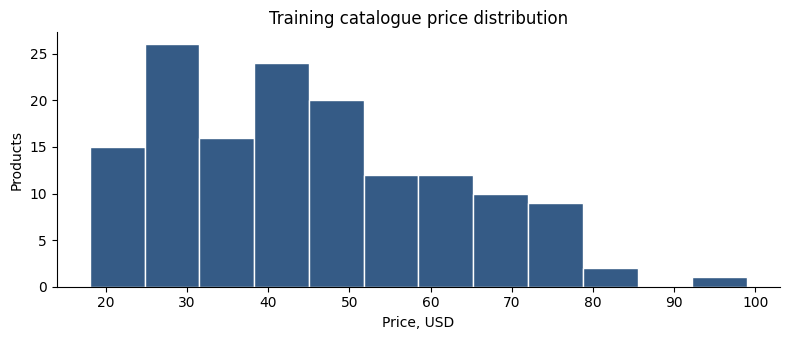

In [9]:
display(browser.price.describe().to_frame("Цена USD"))
fig, ax = plt.subplots(figsize=(8,3.5))
ax.hist(browser.price, bins=12, color="#355b86", edgecolor="white")
ax.set(xlabel="Price, USD", ylabel="Products", title="Training catalogue price distribution")
ax.spines[["top","right"]].set_visible(False)
plt.tight_layout()
plt.show()

## 7. No-code

Manual start / Daily schedule → Render JS → Extract cards → Split cards → Extract fields → Normalize and deduplicate → CSV → Save CSV.

`Render JS` вызывает локальный API с `render_js=true`, нужным селектором и предохранителем 200 товаров. Полный каталог собирается до прекращения прироста; повторные карточки удаляются. API открывает тот же URL, исполняет JS, прокручивает страницу и отдаёт реальный DOM. Это self-hosted rendering API, его код приложен; n8n не запускает наш HTTP-XHR сборщик. На один прогон тратится один запрос рендеринга, внутри него несколько запросов к сайту. Ветка HTTP-ошибки сохраняет CSV и завершает workflow ошибкой. Расписание задано, но workflow не активирован.

Сводные данные измеренного прогона сохранены внутри ноутбука. Новые технические журналы при повторном запуске создаются во временном каталоге. Скриншоты интерфейса n8n показывают дополнительный ручной запуск того же workflow; это отдельно от измеренного CLI-прогона.

In [10]:
nocode = pd.read_csv(ROOT / "nocode/nocode_result.csv")
columns = ["product_id","name","price","currency","url"]
matched = nocode[columns].merge(browser[columns], on=columns, how="inner", validate="one_to_one")
display(nocode.head())
print("n8n:", len(nocode), "совпадений с браузером:",len(matched))
assert len(nocode) == len(browser) == len(light) == len(matched)
assert set(nocode.product_id) == set(browser.product_id) == set(light.product_id)
display(pd.Series(read_json("nocode/run/render_metrics_measured.json")))
display(pd.Series(read_json("nocode/run/error_check.json")))

,snapshot_id,product_id,name,price,currency,url,observed_at
0,1,chaz-kangeroo-hoodie,Chaz Kangeroo Hoodie,52.0,USD,https://scrapingcourse.com/ecommerce/product/c...,2026-10-27T19:09:18.058Z
1,1,teton-pullover-hoodie,Teton Pullover Hoodie,70.0,USD,https://scrapingcourse.com/ecommerce/product/t...,2026-10-27T19:09:18.058Z
2,1,bruno-compete-hoodie,Bruno Compete Hoodie,63.0,USD,https://scrapingcourse.com/ecommerce/product/b...,2026-10-27T19:09:18.058Z
3,1,frankie--sweatshirt,Frankie Sweatshirt,60.0,USD,https://scrapingcourse.com/ecommerce/product/f...,2026-10-27T19:09:18.058Z
4,1,hollister-backyard-sweatshirt,Hollister Backyard Sweatshirt,52.0,USD,https://scrapingcourse.com/ecommerce/product/h...,2026-10-27T19:09:18.058Z


n8n: 147 совпадений с браузером: 147


render_api_calls                                                 1
render_js                                                     True
renderer_peak_rss_mb                                    489.811968
requested_records                                              200
rows                                                           147
seconds                                                   29.01866
site_body_bytes                                             348072
site_requests                                                   26
stop_reason                                            no_growth_2
timestamp                         2026-10-27T19:07:30.059594+00:00
wait_for                [data-testid='product-grid'] .product-item
dtype: object

cli_exit_code                                   1
passed                                       True
timestamp        2026-10-27T19:07:58.127059+00:00
dtype: object

## 8. Выводы и правовая оценка

Для разового исследования достаточно прямого HTML-XHR после диагностики, а n8n удобен для визуального расписания. Для ежедневных 10 000 записей на источнике такого объёма предпочтителен разрешённый API/выгрузка с кэшем, паузами и повторами; текущий каталог конечен и не даёт 10 000 товаров. При антибот-защите нужны разрешение владельца или официальный интерфейс; при CAPTCHA сбор останавливается. Обход защиты и вход в реальные аккаунты в этой работе не выполняются.

Собраны учебные названия, цены, валюта и адреса товаров. Полей, идентифицирующих физических лиц, в этом наборе нет; фамилия студента в оформлении является отдельными персональными сведениями. Содержимое `robots.txt` сохранено в метаданных ноутбука, используется последовательный сбор с паузой 1 с. Адреса товаров и `/ecommerce/*` не посещаются. Robots.txt не является лицензией; данные применяются для учебной проверки, изображения не включены в набор.

Полные источники и сопоставление с требованиями приведены в `report.md`.